M3 – Oracle request 1: initial DOE (15 points)

LHS using pyDOE lib with maximin criterion, over the oracle domain D = 0.35–0.80 m, T = 8–40 N.

In [1]:
!pip install pyDOE

In [2]:
try:
    from pyDOE import lhs      # pyDOE 0.3.x (your Colab version)
except ImportError:
    from pydoe import lhs      # newer pyDOE (>=1.0) installs as lowercase pydoe
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

In [3]:
student_id = "XXXXXXXX"        # <-- put your roll number here

D_min, D_max = 0.35, 0.80      # rotor diameter range (m)  - oracle limits
T_min, T_max = 8.0, 40.0       # thrust per rotor range (N) - oracle limits
n_points = 15

np.random.seed(42)             # fixed seed so the same design comes out every run
lhs_samples = lhs(2, samples=n_points, criterion='maximin', iterations=1000)  # samples in [0,1)
print(lhs_samples)

[[0.70076871 0.54606777]
 [0.78688509 0.35512133]
 [0.4555653  0.77786607]
 [0.04164048 0.60028373]
 [0.51116345 0.42826368]
 [0.27330605 0.8069988 ]
 [0.13406856 0.29892697]
 [0.83546225 0.9859125 ]
 [0.66457148 0.02086538]
 [0.92352572 0.18807257]
 [0.20786449 0.47333754]
 [0.56861014 0.22298632]
 [0.9523212  0.67552309]
 [0.11747345 0.90562421]
 [0.3420539  0.09379527]]


Mapping the sampled lhs values to the actual parameter values (D and T are continuous, so a linear scaling, then rounding to a sensible precision):

In [4]:
samples = []
for s in lhs_samples:                                   # looping in each row
    s_D = round(D_min + s[0]*(D_max - D_min), 3)        # sampled rotor diameter (m)
    s_T = round(T_min + s[1]*(T_max - T_min), 2)        # sampled thrust per rotor (N)
    samples.append([student_id, s_D, s_T])

sample_table = pd.DataFrame(samples, columns=["student_id", "D_m", "T_N"])
print(sample_table)

   student_id    D_m    T_N
0    XXXXXXXX  0.665  25.47
1    XXXXXXXX  0.704  19.36
2    XXXXXXXX  0.555  32.89
3    XXXXXXXX  0.369  27.21
4    XXXXXXXX  0.580  21.70
5    XXXXXXXX  0.473  33.82
6    XXXXXXXX  0.410  17.57
7    XXXXXXXX  0.726  39.55
8    XXXXXXXX  0.649   8.67
9    XXXXXXXX  0.766  14.02
10   XXXXXXXX  0.444  23.15
11   XXXXXXXX  0.606  15.14
12   XXXXXXXX  0.779  29.62
13   XXXXXXXX  0.403  36.98
14   XXXXXXXX  0.504  11.00


Quick checks: all points inside the oracle box, and the maximin distance (in the scaled [0,1] space).

In [5]:
assert sample_table.D_m.between(D_min, D_max).all()
assert sample_table.T_N.between(T_min, T_max).all()
print("Minimum distance between any two points (scaled):", round(pdist(lhs_samples).min(), 3))

# compare against a plain (random) LHS to show what maximin bought us
np.random.seed(0)
plain = [pdist(lhs(2, samples=n_points)).min() for _ in range(200)]
print("Plain LHS, average min distance over 200 tries:", round(np.mean(plain), 3))

Minimum distance between any two points (scaled): 0.184
Plain LHS, average min distance over 200 tries: 0.088


In [6]:
sample_table.to_csv('oracle_request_1.csv', index=False)   # file to email to the TA

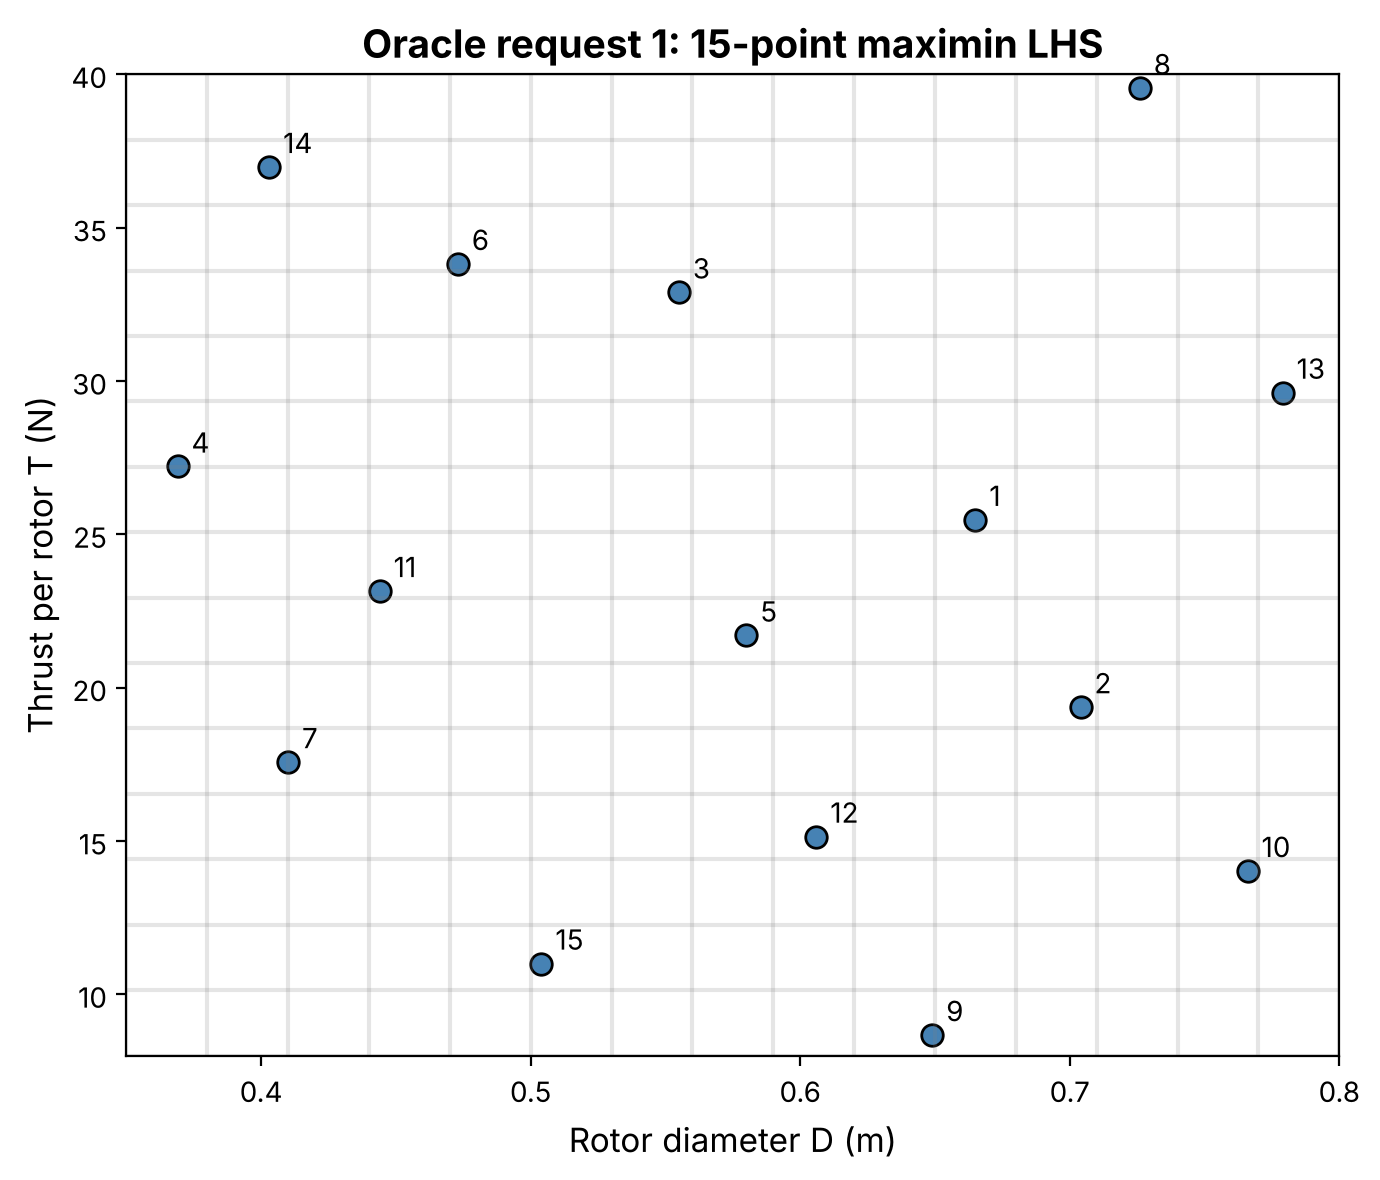

In [7]:
fig = plt.figure(figsize=(7, 6))
plt.scatter(sample_table.D_m, sample_table.T_N, s=60, color='steelblue', edgecolor='black')
for i, r in sample_table.iterrows():
    plt.annotate(str(i+1), (r.D_m, r.T_N), textcoords='offset points', xytext=(5, 5))
# LHS strata lines: each row and each column of the grid holds exactly one point
for k in range(n_points + 1):
    plt.axvline(D_min + k*(D_max-D_min)/n_points, color='grey', alpha=0.2)
    plt.axhline(T_min + k*(T_max-T_min)/n_points, color='grey', alpha=0.2)
plt.xlim(D_min, D_max); plt.ylim(T_min, T_max)
plt.xlabel('Rotor diameter D (m)', fontsize=12)
plt.ylabel('Thrust per rotor T (N)', fontsize=12)
plt.title('Oracle request 1: 15-point maximin LHS', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('oracle_request_1.png', dpi=150)
plt.show()